In [5]:
from qiskit import *
from qiskit.tools.jupyter import *
from qiskit.visualization import *
#from ibm_quantum_widgets import *
import math
from qiskit.circuit.library import QFT
from qiskit import Aer
from qiskit.visualization import plot_histogram
import qiskit.quantum_info as qi
import qiskit

In [13]:
# defining a general Uf
def Uf(a,qc,q):
    for i in range(len(a)):
        if a[i]=='0':
            qc.x(q[len(a)-1-i])
            
    qc.mct(list(range(0,q.size-1)),q[q.size-1])
    
    for i in range(len(a)):
        if a[i]=='0':
            qc.x(q[len(a)-1-i])
            
# our new "oracle"
def U(qc, q):
    num = ['010','100', '110']
    for i in num:
        Uf(i,qc,q)
            
# defining W
def W(qc,q):
    for i in range(q.size-1):
        qc.h(q[i])
        qc.x(q[i])
        
    qc.h(q[q.size-2])
    qc.mct(list(range(0,q.size-2)),q[q.size-2])
    qc.h(q[q.size-2])
    
    for i in range(q.size-1):
        qc.x(q[i])
        qc.h(q[i])

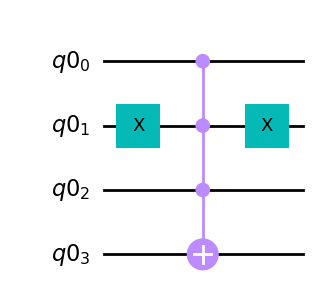

In [7]:
# building Uf for n = 3, a = 5

n = 3
# setting up the quantum circuit
q = QuantumRegister(n+1) # x qubits and 1 ancillary qubit
qc = QuantumCircuit(q)

a = '101'
Uf(a, qc, q)

qc.draw(output = "mpl") # draws out Uf

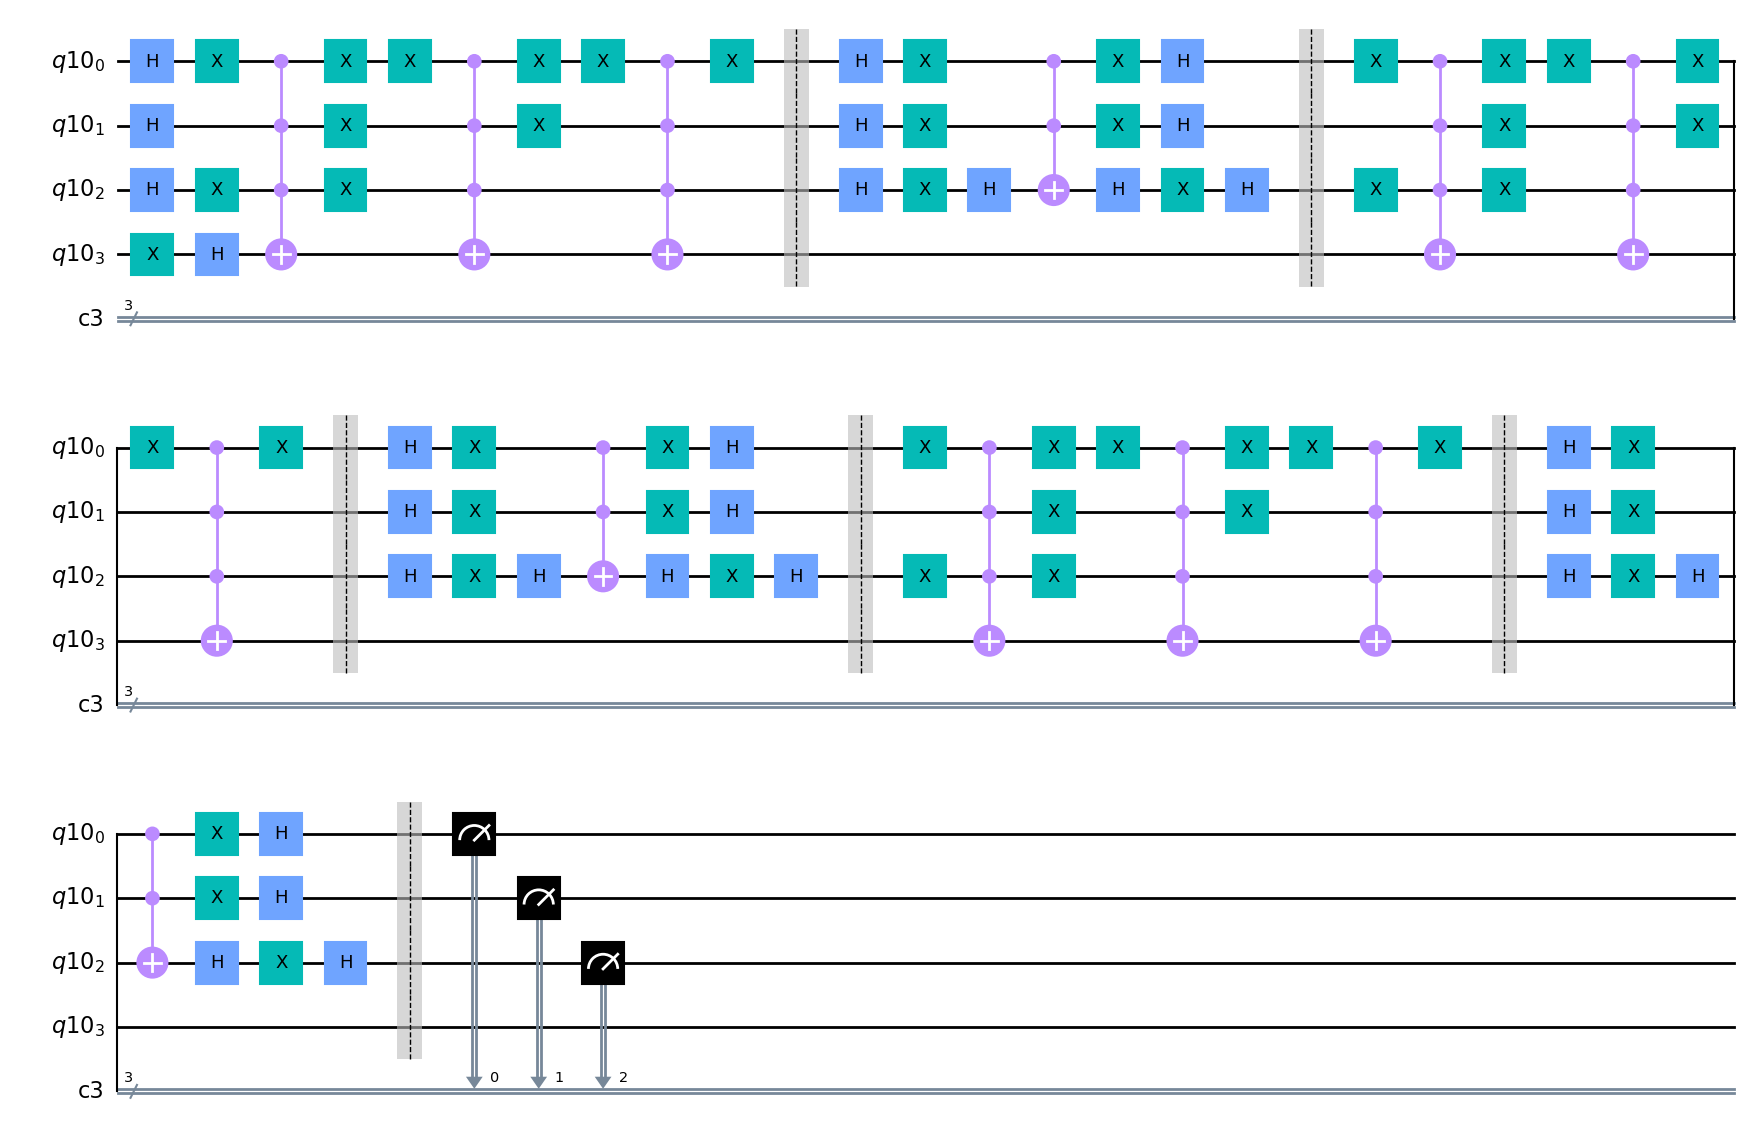

In [14]:
# Grover search!
n = 3
qubits = 4
# create the quantum circuit
qreg1 = QuantumRegister(n+1)
creg1 = ClassicalRegister(n)
qcircuit = QuantumCircuit(qreg1,creg1)
# initialize the one state in the ancillary qubit
qcircuit.x(qreg1[qreg1.size-1])
# put all the qubits in superposition (changes ancillary to minus state)
qcircuit.h(qreg1)

# number of Grover's search iterations
iterations = math.pi/4*math.sqrt(2**(qubits))
a = '101'

for i in range(round(iterations)):
    U(qcircuit, qreg1)
    qcircuit.barrier()
    W(qcircuit, qreg1)
    qcircuit.barrier()
    
qcircuit.measure(qreg1[0:qreg1.size-1],creg1)
qcircuit.draw(output="mpl") # draws out your quantum circuit

{'100': 327, '010': 337, '110': 347, '001': 5, '101': 2, '000': 3, '111': 2, '011': 1}


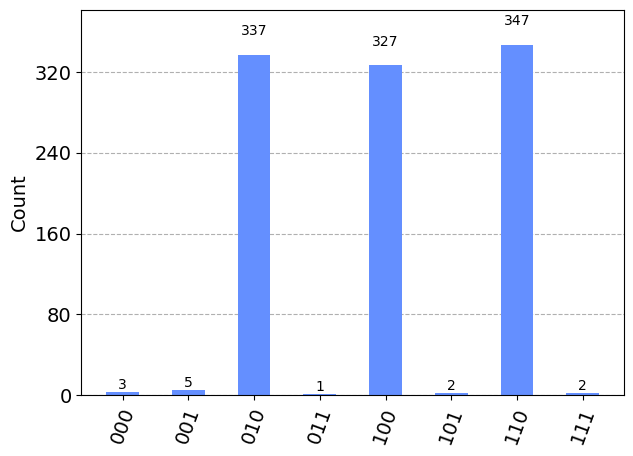

In [19]:
from qiskit import Aer
simulator = Aer.get_backend("qasm_simulator")
job = execute(qcircuit, backend=simulator, shots = 1024)
result = job.result()
counts = result.get_counts(qcircuit)
print(counts)
from qiskit.visualization import plot_histogram
plot_histogram(counts)

## QPE below:

In [43]:
# defining a general Uf gate
def Uf(a,qc,q):
    for i in range(len(a)):
        if a[i]=='0':
            qc.x(q[len(a)-1-i])
            
    qc.mct(list(range(0,q.size-1)),q[q.size-1])
    
    for i in range(len(a)):
        if a[i]=='0':
            qc.x(q[len(a)-1-i])

# our new "oracle"
def U(qc, q):
    #num = ['010','100', '110']
    num = ['0101','1101', '1001', '0001', '1010']
    for i in num:
        Uf(i,qc,q)

# defining W
def W(qc,q):
    for i in range(q.size-1):
        qc.h(q[i])
        qc.x(q[i])
        
    qc.h(q[q.size-2])
    qc.mct(list(range(0,q.size-2)),q[q.size-2])
    qc.h(q[q.size-2])
    
    for i in range(q.size-1):
        qc.x(q[i])
        qc.h(q[i])

In [111]:
# make your custom control gate for Grover operator

def cu(power):
    q=QuantumRegister(n)
    test = QuantumCircuit(q)
    
    
    # constructing the Grover operator to a power
    for i in range(2**power):
        U(test, q)
        W(test,q)
        
        
    c_q = test.to_gate().control()
    
    return c_q

In [129]:
def prepare_initial_state(n, properties):
    """
    Prepares the initial state with nodes in superposition and an extra property qubit.
    
    Parameters:
        num_nodes (int): Total number of nodes in the graph.
        properties (list[int]): List of properties for each node (0 = maximal, 1 = maximal-but-one).
                                The length of the list should be `num_nodes`.
                                
    Returns:
        QuantumCircuit: The circuit preparing the initial state.
    """
    total_qubits = n # Index qubits + property qubit + ancillary qubits
    
    q=QuantumRegister(total_qubits)
    qc = QuantumCircuit(q, name='initial_state')
    
    # Step 1: Create uniform superposition over node indices
    qc.h(range(n))
    
    # Step 2: Encode the property into the property qubit
    for i, property_value in enumerate(properties):
        binary_index = format(i, f'0{n-1}b')
        for qubit, bit in enumerate(binary_index):
            if bit == '0':
                qc.x(qubit)  # Flip to match the binary representation of i
        
        # Flip the property qubit if the property value is 1
        if property_value == 1:
            qc.mcx(list(range(n-1)), n-1)  # Multi-controlled X gate
        
        for qubit, bit in enumerate(binary_index):
            if bit == '0':
                qc.x(qubit)  # Undo the flip
    
    qc.draw(output="mpl")
    return qc
    

4


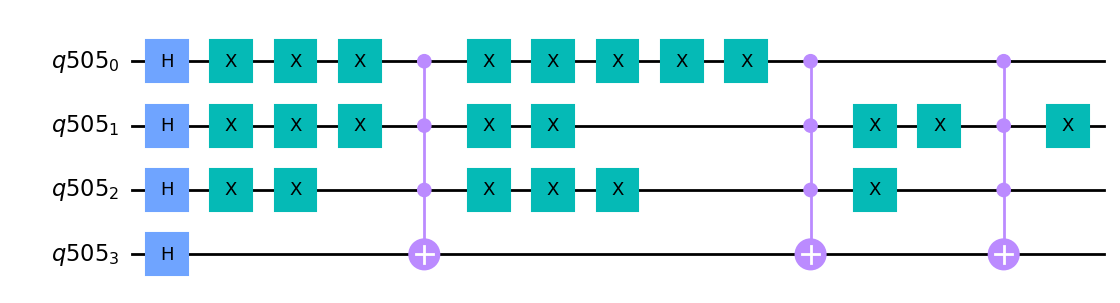

In [131]:
# quantum phase estimation

# number of ancillary qubits only for QPE:
anc = 8 # this is the value of t
nodes = 6
n = nodes.bit_length() + 1
print(n)
# making the quantum circuit
q=QuantumRegister(n+anc)
creg = ClassicalRegister(anc)
qc = QuantumCircuit(q,creg)

# setting up the eigenvector, which is the initial state of the input register in Grover's search
# setting up the Hadamards on the ancillay qubits in QPE

#qc, q, creg, n = prepare_initial_state(nodes, [0, 1, 0, 0, 1, 1], anc)

# qc.x(q[q.size-1])
initalisation_qc = prepare_initial_state(n, [0, 1, 0, 0, 1, 1])
initalisation_qc.draw(output="mpl")

# qc.append(initalisation_qc, q[anc:n+anc])
# qc.h(q[0:anc])#q.size])

# t = creg.size   

# # adding the control gates
# for i in range(t):
#     index_list = [i]
#     index_list+=list(range(t,q.size))
#     qc.append(cu(i),index_list)
          
# # inverse quantum fourier transform
# qc.append(QFT(t).inverse(), q[0:t])
          
# qc.measure(q[0:t],creg)

# qc.draw(output="mpl") # draw out the quantum circuit for QPE

In [128]:
# Results from running QPE
from qiskit import Aer
simulator = Aer.get_backend("qasm_simulator")
job = execute(qc, backend=simulator, shots = 1024)
result = job.result()
counts1 = result.get_counts(qc)
print(counts1)

# Gets the most frequent value from counts1, which is the j that QPE returns
freq = qiskit.result.Counts.most_frequent(counts1)
qpe_result = int(freq,2)

# number of marked elements:
m = 2**(qubits)*(math.sin(math.pi*qpe_result/(2**t) + math.pi/2)**2)
print(m)

{'10000000': 1024}
2.399615652258972e-31
